# Jupyter Notebook 2. Эксперименты с моделями и валидация

**Стажёр:** [Имя]

На входе — готовый датасет, подготовленный ранее и разделённый на тренировочную и тестовую выборки.

На выходе — финальная модель, карточка модели и SHAP-анализ.

## 1.Подключение библиотек

In [1]:
# если не установлена раскомментировать
!pip install lightgbm catboost optuna shap boto3 python-dotenv -q

In [2]:
# для использования кредов из .env
from dotenv import load_dotenv
load_dotenv()

False

In [3]:
import io, os, json, boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline

from lightgbm import LGBMClassifier

import catboost
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score, precision_recall_curve, classification_report

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.model_selection import train_test_split

from pathlib import Path

import shap

In [4]:
# проверка для совместимости между средами jupyter notebook и airflow
import sys
print("python  ", sys.version.split()[0])
print("numpy   ", np.__version__)
print("pandas  ", pd.__version__)
print("catboost", catboost.__version__)

python   3.13.16
numpy    2.1.3
pandas   2.2.3
catboost 1.2.10


In [6]:
# для inference загружаем обработанные данные в S3
# из .env
extras = {
    "bucket": os.getenv("S3_BUCKET"),
    "endpoint_url": os.getenv("S3_ENDPOINT_URL"),
    "aws_access_key_id": os.getenv("AWS_ACCESS_KEY_ID"),
    "aws_secret_access_key": os.getenv("AWS_SECRET_ACCESS_KEY"),
}

s3 = boto3.client(
    "s3",
    aws_access_key_id=extras.get("aws_access_key_id"),
    aws_secret_access_key=extras.get("aws_secret_access_key"),
    endpoint_url=extras.get("endpoint_url"),
)

BUCKET = extras["bucket"]
DATA_KEY = "smartscore/data/processed_data.joblib"          # данные для обучения
MODEL_PREFIX = "models/high_demand_catboost/v1/"

In [7]:
# с помощью get_object забираем из S3 ,frtnf содержимое файла потоком
obj = s3.get_object(Bucket=BUCKET, Key=DATA_KEY)
# BytesIO делает из байтов файл в памяти, а joblib.load разворачивает словарь processed_data
processed_data = joblib.load(io.BytesIO(obj["Body"].read()))

X_train = processed_data["X_train"]
X_test = processed_data["X_test"]
y_train = processed_data["y_train"]
y_test = processed_data["y_test"]
categorical_features = processed_data["categorical_features"]
numeric_features = processed_data["numeric_features"]
text_feature = processed_data["text_feature"]
rf_preprocessor = processed_data["rf_preprocessor"]
lgbm_preprocessor = processed_data["lgbm_preprocessor"]

## 2.Загрузка данных

Загрузите `train` и `test` выборки из тетради 1. Проверьте размеры выборок и баланс классов.

**Баланс классов в `train` и `test`:**

In [8]:
X_train.shape

(88894, 31)

In [9]:
X_test.shape

(22224, 31)

In [10]:
y_train.shape

(88894,)

In [11]:
y_test.shape

(22224,)

In [12]:
X_train.columns

Index(['room_type', 'host_response_time', 'host_is_superhost',
       'host_identity_verified', 'minimum_nights', 'maximum_nights',
       'instant_bookable', 'accommodates', 'bedrooms', 'beds', 'bathrooms',
       'latitude', 'longitude', 'host_acceptance_rate',
       'host_total_listings_count', 'host_has_profile_pic',
       'calculated_host_listings_count_entire_homes',
       'calculated_host_listings_count_private_rooms',
       'calendar_availability_rate', 'avg_recent_comment_len',
       'property_type_top', 'amenities_count', 'filtered_sentences',
       'filtered_name', 'days_since_last_review', 'review_span_days',
       'host_tenure_days', 'calendar_closed', 'is_long_stay',
       'guests_per_bedroom', 'guests_per_bathroom'],
      dtype='object')

## 3.Baseline

Постройте простую базовую модель: она задаст точку отсчёта для всех последующих экспериментов. Если сложная модель едва бьёт baseline — стоит задуматься.

Зафиксируйте метрики базовой модели в таблице экспериментов далее в этом уроке.

В качестве базовой модели Random Forest Classifier (через Pipeline + cross_validate)

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [14]:
rf_pipeline = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'))
])

rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=['roc_auc', 'average_precision', 'f1', 'precision', 'recall'],
    n_jobs=-1
)

print("Random Forest CV Metrics")
print(f"PR-AUC:    {rf_cv['test_average_precision'].mean():.4f} +/- {rf_cv['test_average_precision'].std():.4f}"
      f"   (случайная модель ≈ {y_train.mean():.3f})")
print(f"ROC-AUC:   {rf_cv['test_roc_auc'].mean():.4f} +/- {rf_cv['test_roc_auc'].std():.4f}")
print(f"F1-Score:  {rf_cv['test_f1'].mean():.4f}")
print(f"Precision: {rf_cv['test_precision'].mean():.4f}")
print(f"Recall:    {rf_cv['test_recall'].mean():.4f}")

Random Forest CV Metrics
PR-AUC:    0.5800 +/- 0.0044   (случайная модель ≈ 0.132)
ROC-AUC:   0.8933 +/- 0.0024
F1-Score:  0.2762
Precision: 0.8011
Recall:    0.1669


**Метрики baseline и выводы:**

Random Forest в качестве baseline со стандартным порогом 0.5 имеет метрики:

PR-AUC:    0.5800

ROC-AUC:   0.8933

F1-Score:  0.2762

Precision: 0.8011

Recall:    0.1669.

Baseline служит точкой отсчёта.

## 4.Эксперименты с моделями

Попробуйте обучить разные модели и наборы признаков. Каждый эксперимент фиксируйте в таблице.

> Если класс несбалансирован, то учитывайте это при выборе метрик и настройке моделей. Обоснуйте выбор.

> Тестовая выборка используется **только один раз** — для финальной оценки лучшей модели. Не используйте её во время экспериментов.

Загрузка и K-Fold Кросс-Валидация

Для классификации используется StratifiedKFold (чтобы сохранить баланс классов в каждом фолде) и метрики классификации (pr-auc,roc_auc, f1, precision,recall)

### 4.1 Таблица экспериментов

Заполняйте таблицу по мере обучения моделей:

| № | Алгоритм | Признаки | Дисбаланс | PR-AUC |ROC-AUC | F1 | Precision | Recall | Примечание |
|---|----------|----------|-----------|---------|---------|----|-----------|---------|-----------|
| 1 | Baseline Random Forest | — | — |0.5800 |0.8933|0.2762 |0.8011 |0.1669 | |
| 2 | LightGBM Classifier| | |0.6437 |0.9161 |0.5596 |0.4197 |0.8394 |
| 3 | CatBoost Classifie| | |0.6660 |0.9227 |0.5889 |0.4593 |0.8204 |
| 4 | | | | | | | | |
| 5 | | | | | | | | |

### 4.2 Эксперименты

#### **Эксперимент 1: LightGBM Classifier (через Pipeline + cross_validate)**

Random Forest и LightGBM не умеют работать со строками. Поэтому текст превращается в числа заранее, внутри пайплайна (preprocessor:TfidfVectorizer: текст - n числовых столбцов)

In [15]:
# Эксперимент 1 LGBM
lgbm_pipeline = Pipeline([
    ('preprocessor', lgbm_preprocessor),
    ('classifier', LGBMClassifier(random_state=42, class_weight='balanced', verbose=-1))
])

# категориальные признаки идут первыми в матрице после ColumnTransformer
n_cat = len(categorical_features)

scoring = ['roc_auc', 'average_precision', 'f1', 'precision', 'recall']

lgbm_cv = cross_validate(
    lgbm_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    params={'classifier__categorical_feature': list(range(n_cat))},
    n_jobs=2
)

print("LightGBM CV Metrics")
print(f"PR-AUC:    {lgbm_cv['test_average_precision'].mean():.4f} +/- {lgbm_cv['test_average_precision'].std():.4f}"
      f"   (случайная модель ≈ {y_train.mean():.3f})")
print(f"ROC-AUC:   {lgbm_cv['test_roc_auc'].mean():.4f} +/- {lgbm_cv['test_roc_auc'].std():.4f}")
print(f"F1-Score:  {lgbm_cv['test_f1'].mean():.4f}")
print(f"Precision: {lgbm_cv['test_precision'].mean():.4f}")
print(f"Recall:    {lgbm_cv['test_recall'].mean():.4f}")

LightGBM CV Metrics
PR-AUC:    0.6437 +/- 0.0019   (случайная модель ≈ 0.132)
ROC-AUC:   0.9161 +/- 0.0014
F1-Score:  0.5596
Precision: 0.4197
Recall:    0.8394


Метрики LightGBM Classifier:

PR-AUC:    0.6437  (случайная модель ≈ 0.132)

ROC-AUC:   0.9161

F1-Score:  0.5596

Precision: 0.4197

Recall:    0.8394

#### **Эксперимент 2: CatBoost Classifier (с явным ручным циклом StratifiedKFold)**

CatBoost умеет работать с текстом сам: ему можно отдать строку, и он внутри построит по ней признаки. Но он должен знать, какие столбцы являются текстом (а какие категориями), иначе посчитает их обычными. Удобнее применить ручной цикл по фолдам:

In [16]:
# в качестве параметра text_features CatBoost требуется список
# для случая если только 1 текстовый признак передается text_cols - всегда будет списоком
text_cols = [text_feature] if isinstance(text_feature, str) else text_feature

In [17]:
# преобразуем категориальные признаки в str для CatBoost
X_cb = X_train.copy()
for c in categorical_features:
    X_cb[c] = X_cb[c].astype(str)

In [18]:
# Эксперимент 2 CATBOOST

# для быстрой проверки на сэмпле
#idx = X_train.sample(20000, random_state=42).index
#X_cb =  X_train.loc[idx].copy()
#y_small = y_train.loc[idx]

# out-of-fold для cb_model - предсказание для каждой строки train
oof_cb = np.zeros(len(X_train))

metrics = {'pr_auc': [], 'roc_auc': [], 'f1': [], 'precision': [], 'recall': []}

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cb, y_train)):
    X_tr, y_tr = X_cb.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_cb.iloc[val_idx], y_train.iloc[val_idx]

    train_pool = Pool(X_tr, y_tr, cat_features=categorical_features, text_features=text_cols)
    val_pool = Pool(X_va, y_va, cat_features=categorical_features, text_features=text_cols)

    cb_model = CatBoostClassifier(
        iterations=500,
        random_state=42,
        auto_class_weights='Balanced',
        verbose=0
    )
    # без eval_set и early stopping: оценка на фолде не должна влиять на обучение
    cb_model.fit(train_pool)

    proba = cb_model.predict_proba(val_pool)[:, 1]

    oof_cb[val_idx] = proba

    pred = (proba >= 0.5).astype(int)   # тот же порог, что у RF и LightGBM

    metrics['pr_auc'].append(average_precision_score(y_va, proba))
    metrics['roc_auc'].append(roc_auc_score(y_va, proba))
    metrics['f1'].append(f1_score(y_va, pred))
    metrics['precision'].append(precision_score(y_va, pred, zero_division=0))
    metrics['recall'].append(recall_score(y_va, pred))

    print(f"Fold {fold + 1} | PR-AUC: {metrics['pr_auc'][-1]:.4f} | "
          f"ROC-AUC: {metrics['roc_auc'][-1]:.4f} | F1: {metrics['f1'][-1]:.4f}")

print("CatBoost CV Metrics")
print(f"PR-AUC:    {np.mean(metrics['pr_auc']):.4f} +/- {np.std(metrics['pr_auc']):.4f}"
      f"   (случайная модель ≈ {y_train.mean():.3f})")
print(f"ROC-AUC:   {np.mean(metrics['roc_auc']):.4f} +/- {np.std(metrics['roc_auc']):.4f}")
print(f"F1-Score:  {np.mean(metrics['f1']):.4f}")
print(f"Precision: {np.mean(metrics['precision']):.4f}")
print(f"Recall:    {np.mean(metrics['recall']):.4f}")

Fold 1 | PR-AUC: 0.6689 | ROC-AUC: 0.9219 | F1: 0.5910
Fold 2 | PR-AUC: 0.6648 | ROC-AUC: 0.9236 | F1: 0.5903
Fold 3 | PR-AUC: 0.6649 | ROC-AUC: 0.9206 | F1: 0.5838
Fold 4 | PR-AUC: 0.6618 | ROC-AUC: 0.9228 | F1: 0.5869
Fold 5 | PR-AUC: 0.6694 | ROC-AUC: 0.9247 | F1: 0.5924
CatBoost CV Metrics
PR-AUC:    0.6660 +/- 0.0028   (случайная модель ≈ 0.132)
ROC-AUC:   0.9227 +/- 0.0014
F1-Score:  0.5889
Precision: 0.4593
Recall:    0.8204


Результаты эксперимента 2 CatBoost:

Fold 1 | PR-AUC: 0.6689 | ROC-AUC: 0.9219 | F1: 0.5910

Fold 2 | PR-AUC: 0.6648 | ROC-AUC: 0.9236 | F1: 0.5903

Fold 3 | PR-AUC: 0.6649 | ROC-AUC: 0.9206 | F1: 0.5838

Fold 4 | PR-AUC: 0.6618 | ROC-AUC: 0.9228 | F1: 0.5869

Fold 5 | PR-AUC: 0.6694 | ROC-AUC: 0.9247 | F1: 0.5924

CatBoost CV Metrics

PR-AUC:    0.6660 +/- 0.0028   (случайная модель ≈ 0.132)

ROC-AUC:   0.9227 +/- 0.0014

F1-Score:  0.5889

Precision: 0.4593

Recall:    0.8204

**Выводы по экспериментам:**

Random Forest при пороге 0.5 ведёт себя очень осторожно. Он редко выдаёт вероятность выше 0.5, поэтому Precision высокая (0.80), а Recall низкий (0.16). F1 = 0.27 говорит не о слабой модели, а о неподходящем пороге.

LightGBM и CatBoost с балансировкой классов уходят в другую крайность. Они находят 82–83% положительных объектов (Recall), но платят за это точностью (Precision 0.42–0.46).

F1 у них выше только потому, что порог ближе к оптимальному.

Лучший по качеству ранжирования — CatBoost. Его PR-AUC выше, чем у LightGBM, на 0.02. LightGBM, в свою очередь, заметно лучше Random Forest (+0.06).

Все модели значительно лучше случайной. Случайная модель даёт PR-AUC около 0.1. У CatBoost 0.666. Разброс по фолдам небольшой, значит, оценка устойчива.

Выводы по кросс-валидации.
Основная метрика — PR-AUC, поскольку класс редкий (≈10%) и метрика не зависит от порога.

По ней лучшей моделью оказался CatBoost (0.666), за ним следуют LightGBM (0.64) и Random Forest (0.58).


В качестве основной модели выбран CatBoost; LightGBM остаётся второй кандидатной моделью.


| № | Алгоритм | Признаки | Дисбаланс | PR-AUC | ROC-AUC | F1 | Precision | Recall |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | Random Forest (baseline) | Все 31, TF-IDF 100 | `class_weight='balanced'` | 0.5800 |0.8933|0.2762 |0.8011 |0.1669 |
| 2 | LightGBM | Все 31, TF-IDF 100 | `class_weight='balanced'` | 0.6437 |0.9161 |0.5596 |0.4197 |0.8394 |
| 3 | CatBoost | Все 31, нативный текст | `auto_class_weights='Balanced'` | 0.6660 |0.9227 |0.5889 |0.4593 |0.8204 |

## 5.Подбор гиперпараметров

Для лучшей модели из экспериментов подберите гиперпараметры через Optuna. Зафиксируйте лучшие параметры и итоговые метрики.

In [19]:
N_TRIALS = 8        # из-а долгого обучения уменьшен до 8
TUNE_SIZE = 20_000   # подбор на подвыборке train для скорости

# Подвыборка для подбора (стратифицированная)
X_tune_cb, _, y_tune, _ = train_test_split(X_cb, y_train,
                                        train_size=TUNE_SIZE,
                                        stratify=y_train,
                                        random_state=42)

tune_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def cb_objective(trial):
    params = dict(
        iterations=trial.suggest_int('iterations', 200, 800, step=200),
        learning_rate=trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
        depth=trial.suggest_int('depth', 4, 8),
        l2_leaf_reg=trial.suggest_float('l2_leaf_reg', 1, 10, log=True),
        rsm=trial.suggest_float('rsm', 0.5, 1.0),
    )
    scores = []
    for tr, va in tune_skf.split(X_tune_cb, y_tune):
        tr_pool = Pool(X_tune_cb.iloc[tr], y_tune.iloc[tr],
                       cat_features=categorical_features, text_features=text_cols)
        va_pool = Pool(X_tune_cb.iloc[va], y_tune.iloc[va],
                       cat_features=categorical_features, text_features=text_cols)
        m = CatBoostClassifier(**params, random_state=42,
                               auto_class_weights='Balanced', verbose=0)
        m.fit(tr_pool)
        scores.append(average_precision_score(y_tune.iloc[va], m.predict_proba(va_pool)[:, 1]))
    return np.mean(scores)

cb_study = optuna.create_study(direction='maximize',
                               sampler=optuna.samplers.TPESampler(seed=42))
cb_study.optimize(cb_objective, n_trials=N_TRIALS, show_progress_bar=True)

cb_best = cb_study.best_params
print("PR-AUC при подборе:", round(cb_study.best_value, 4))
print("Лучшие параметры:", cb_best)

  0%|          | 0/8 [00:00<?, ?it/s]

PR-AUC при подборе: 0.6303
Лучшие параметры: {'iterations': 800, 'learning_rate': 0.031674063118237505, 'depth': 6, 'l2_leaf_reg': 3.9121416285496955, 'rsm': 0.5232252063599989}


#### **Лучшие параметры и метрики после подбора:**

* PR-AUC при подборе: 0.6303
* Лучшие параметры: {'iterations': 800, 'learning_rate': 0.031674063118237505, 'depth': 6, 'l2_leaf_reg': 3.9121416285496955, 'rsm': 0.5232252063599989}

Подбор гиперпараметров CatBoost выполнен через Optuna (8 trials, TPE) на стратифицированной подвыборке 20 000 строк с 3-фолдовой валидацией.

Значение PR-AUC на подвыборке (0.63) не сопоставимо с результатом кросс-валидации на полной обучающей выборке (0.67), так как выборка и схема валидации различаются.

Окончательное решение об использовании подобранных параметров принимается по результатам проверки на полном X_train с теми же 5 фолдами, что и у базовой модели.

#### Кросс-валидация на полном train с лучшими параметрами, с cb_best:


Проверяем дал ли подбор гиперпараметров прирост по метрике PR-AUC


In [20]:
cb_best =  {'iterations': 800, 'learning_rate': 0.031674063118237505, 'depth': 6, 'l2_leaf_reg': 3.9121416285496955, 'rsm': 0.5232252063599989}

In [21]:
# Два пустых списка для PR-AUC и ROC-AUC каждого фолда
fold_pr, fold_roc = [], []

for fold, (train_idx, val_idx) in enumerate(skf.split(X_cb, y_train)):
    X_tr, y_tr = X_cb.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_cb.iloc[val_idx], y_train.iloc[val_idx]

    train_pool = Pool(X_tr, y_tr, cat_features=categorical_features, text_features=text_cols)
    val_pool = Pool(X_va, y_va, cat_features=categorical_features, text_features=text_cols)

    cb_model = CatBoostClassifier(**cb_best, random_state=42,
                                  auto_class_weights='Balanced', verbose=0)
    cb_model.fit(train_pool)

    proba = cb_model.predict_proba(val_pool)[:, 1]

    fold_pr.append(average_precision_score(y_va, proba))
    fold_roc.append(roc_auc_score(y_va, proba))
    print(f"Fold {fold + 1} | PR-AUC: {fold_pr[-1]:.4f} | ROC-AUC: {fold_roc[-1]:.4f}")

print("CatBoost (настроенный) CV")
print(f"PR-AUC:  {np.mean(fold_pr):.4f} +/- {np.std(fold_pr):.4f}")
print(f"ROC-AUC: {np.mean(fold_roc):.4f} +/- {np.std(fold_roc):.4f}")

Fold 1 | PR-AUC: 0.6646 | ROC-AUC: 0.9199
Fold 2 | PR-AUC: 0.6542 | ROC-AUC: 0.9187
Fold 3 | PR-AUC: 0.6575 | ROC-AUC: 0.9180
Fold 4 | PR-AUC: 0.6591 | ROC-AUC: 0.9212
Fold 5 | PR-AUC: 0.6636 | ROC-AUC: 0.9224
CatBoost (настроенный) CV
PR-AUC:  0.6598 +/- 0.0039
ROC-AUC: 0.9200 +/- 0.0016


**Результат подобранные гиперпараметры CatBoost на полном train:**

Fold 1 | PR-AUC: 0.6646 | ROC-AUC: 0.9199

Fold 2 | PR-AUC: 0.6542 | ROC-AUC: 0.9187

Fold 3 | PR-AUC: 0.6575 | ROC-AUC: 0.9180

Fold 4 | PR-AUC: 0.6591 | ROC-AUC: 0.9212

Fold 5 | PR-AUC: 0.6636 | ROC-AUC: 0.9224

CatBoost (настроенный) CV

PR-AUC:  0.6598 +/- 0.0039

ROC-AUC: 0.9200 +/- 0.0016

Подбор гиперпараметров CatBoost выполнен через Optuna (8 trials, TPE, подвыборка 20 000 строк, 3 фолда).

Найденные параметры (cb_best =  {'iterations': 800, 'learning_rate': 0.031674063118237505, 'depth': 6, 'l2_leaf_reg': 3.9121416285496955, 'rsm': 0.5232252063599989}) проверены на полном обучающем наборе теми же 5 фолдами, что и базовая модель.

Результат: PR-AUC 0.6598 хуже против 0.6660 у CatBoost модели с параметрами по умолчанию , ROC-AUC 0.9200 против 0.9227.

Вывод: Подбор не дал улучшения. Поэтому в качестве финальной выбрана базовая конфигурация CatBoost (500 итераций, параметры по умолчанию).

Подбор порога по out-of-fold вероятностям

#### Подбор порога

In [22]:
# подбор порога с out-of-fold вероятностями, рассчитанными в эксперименте 2
prec, rec, thr = precision_recall_curve(y_train, oof_cb)
f1 = 2 * prec * rec / (prec + rec + 1e-12)

# находим максимум F1
b = np.argmax(f1[:-1])
threshold = thr[b]
print(f"Порог по максимуму F1: {threshold:.3f} | F1={f1[b]:.3f} | "
      f"precision={prec[b]:.3f} | recall={rec[b]:.3f}")

Порог по максимуму F1: 0.684 | F1=0.620 | precision=0.577 | recall=0.670


Порог по максимуму F1: 0.684 | F1=0.620 | precision=0.577 | recall=0.670

## 6. Выбор финальной модели

Обоснуйте выбор финальной модели. Опирайтесь не только на метрики, но и на бизнес-контекст и связь с EDA.

**Обоснование выбора финальной модели:**

- Алгоритм:
  * CatBoostClassifier (градиентный бустинг), 500 итераций, параметры по умолчанию, auto_class_weights='Balanced'.
  
  * Порог классификации 0.68 подобран по максимуму F1 на out-of-fold предсказаниях.

- Признаки:
  * 31 признака: 7 категориальных, 2 текстовых (filtered_name, filtered_sentences), 22 числовых, включая созданные в feature engineering (amenities_count, guests_per_bedroom, calendar_closed, is_long_stay, host_tenure_days и др.).
  
  * Категории и тексты передаются в CatBoost напрямую, пропуски в числовых признаках оставлены как NaN.

- Метрики на валидации:
  * (5-fold, out-of-fold):
    - PR-AUC [0.6659] (случайная модель ≈ 0.1),
    - ROC-AUC [0.9227].
    
    При пороге 0.684:
    * Precision [0.5773],
    * Recall [0.6703],
    * F1 [0.6203].

    При стандартном пороге 0.5:
    * Precision 0.4593,
    * Recall 0.8204,
    * F1 0.5889

- Почему лучше других:
  * по основной метрике PR-AUC CatBoost (0.66) превосходит LightGBM (0.64) и Random Forest (0.58).
  
  * Модель использует тексты и категории напрямую, без потерь на кодировании и без ограничения TF-IDF в 100 слов.

- Связь с бизнес-задачей:
  * Целевой класс редкий (≈10%), поэтому основная метрика PR-AUC, а порог подобран отдельно, чтобы получить баланс между точностью и полнотой.
  * Тексты названий и отзывов использованы как текстовые признаки.
  * Модель позволяет выделять листинги с высоким спросом для повышения конверсии.

️️После того как финальная модель выбрана, её необходимо сохранить как артефакт.

Сохраните модель в S3, чтобы она могла быть использована в продакшен-пайплайне.


Финальное обучение и сохранение лучшего пайплайна для батч-инференса
Когда определите лучшую модель (например, LightGBM), обучите полный Pipeline (препроцессор + модель) на всём X_train и сохраните единый артефакт:

In [23]:
# параметры для CaBoost задаем из эксперимента 2
cb_params = {
    'iterations': 500,
    'random_state': 42,
    'auto_class_weights': 'Balanced',
    'verbose': 0
}

In [24]:
# Финальная модель CatBoost на полном train
full_pool = Pool(X_cb, y_train, cat_features=categorical_features, text_features=text_cols)
final_cb = CatBoostClassifier(**cb_params)
final_cb.fit(full_pool)

CatBoostClassifier(auto_class_weights='Balanced', iterations=500, random_state=42, verbose=0)

In [25]:
# метрики на валидации с порогом:
oof_pred = (oof_cb >= threshold).astype(int)

print(f"PR-AUC:    {average_precision_score(y_train, oof_cb):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_train, oof_cb):.4f}")
print(f"Порог:     {threshold:.3f}")
print(f"Precision: {precision_score(y_train, oof_pred):.4f}")
print(f"Recall:    {recall_score(y_train, oof_pred):.4f}")
print(f"F1-Score:  {f1_score(y_train, oof_pred):.4f}")

PR-AUC:    0.6659
ROC-AUC:   0.9227
Порог:     0.684
Precision: 0.5773
Recall:    0.6703
F1-Score:  0.6203


метрики CatBoost (финальная модель с параметрами по умолчанию) на валидации train с порогом:

PR-AUC:    0.6659

ROC-AUC:   0.9227

Порог:     0.684

Precision: 0.5773

Recall:    0.6703

F1-Score:  0.6203

Сохранение финальной модели в S3

У CatBoost отдельного препроцессора нет: он сам обрабатывает категории и тексты.

Единственная подготовка данных, то есть перевод категорий в строки и замена пропусков в тексте на пустую строку, описана в файле метаданных.

In [26]:
# сохраняем модель
final_cb.save_model('catboost_final.cbm')

# сохраняем всё, что нужно для применения модели
meta = {
    'threshold': float(threshold),
    'features': X_cb.columns.tolist(),
    'categorical_features': categorical_features,
    'text_features': text_cols,
    'params': {'iterations': 500, 'random_state': 42, 'auto_class_weights': 'Balanced'}
}

with open('catboost_meta.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

In [27]:
# проверка: список признаков в мета-файле совпадает с признаками модели
print(meta['features'] == list(final_cb.feature_names_))     # должно быть True
print(len(meta['features']), len(meta['categorical_features']))   # 31 и 7

True
31 7


In [28]:
# Загружаем в S3
s3.upload_file('catboost_final.cbm', BUCKET, MODEL_PREFIX + 'catboost_final.cbm')
s3.upload_file('catboost_meta.json', BUCKET, MODEL_PREFIX + 'catboost_meta.json')
print(f"Сохранено: s3://{BUCKET}/{MODEL_PREFIX}")

Сохранено: s3://s3-ds-20260714-53fe25f3f1/models/high_demand_catboost/v1/


In [29]:
# проверка наличия файлов в S3
for name in ["catboost_final.cbm", "catboost_meta.json", "preprocess_artifacts.json"]:
    info = s3.head_object(Bucket=BUCKET, Key=MODEL_PREFIX + name)
    print(name, round(info["ContentLength"] / 1e3, 1), "КБ")

catboost_final.cbm 9411.7 КБ
catboost_meta.json 1.2 КБ
preprocess_artifacts.json 14.5 КБ


## 7. Валидация на тестовой выборке

Только сейчас — после того, как финальная модель выбрана, — нужно перейти к работе с тестовой выборкой. Сравните метрики лучшей модели на валидации и на тесте. Есть ли симптомы переобучения?

In [30]:
# преобразование категориальных призанков к типу str для CatBoost
X_test_cb = X_test.copy()
for c in categorical_features:
    X_test_cb[c] = X_test_cb[c].astype(str)

In [31]:
# Тест
test_pool = Pool(X_test_cb, y_test, cat_features=categorical_features, text_features=text_cols)
test_proba = final_cb.predict_proba(test_pool)[:, 1]
test_pred = (test_proba >= threshold).astype(int)

print("Финальная оценка на тесте")
print(f"PR-AUC:    {average_precision_score(y_test, test_proba):.4f}   (случайная модель ≈ {y_test.mean():.3f})")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_proba):.4f}")
print(f"Порог:     {threshold:.3f}")
print(f"Precision: {precision_score(y_test, test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, test_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, test_pred):.4f}")
print(classification_report(y_test, test_pred, digits=3))

Финальная оценка на тесте
PR-AUC:    0.6934   (случайная модель ≈ 0.132)
ROC-AUC:   0.9298
Порог:     0.684
Precision: 0.5987
Recall:    0.6856
F1-Score:  0.6392
              precision    recall  f1-score   support

           0      0.951     0.930     0.941     19301
           1      0.599     0.686     0.639      2923

    accuracy                          0.898     22224
   macro avg      0.775     0.808     0.790     22224
weighted avg      0.905     0.898     0.901     22224



In [32]:
len(X_test_cb)

22224

**Метрики на тесте и выводы:**

* На отложенной тестовой выборке (22224 объектов, доля целевого класса 10%) финальная модель показала PR-AUC 0.6934 (случайная модель ≈ 0.132) и ROC-AUC 0.9298. При пороге 0.684, подобранном по out-of-fold предсказаниям, Precision составила 0.5987, Recall 0.6856, F1 0.6392.

Модель находит около 68,56% листингов с высоким спросом, при этом 59% её срабатываний верны. Accuracy 0.898 малоинформативна из-за дисбаланса.

Сравнение с валидацией. Небольшое улучшение PR-AUC на тесте (0.6934) выше на 0.027 среднего по кросс-валидации (0.6660), ROC-AUC практически идентичен (0.9298 и 0.9227).

* признаков переобучения нет.

* Финальная оценка на тесте:

  * PR-AUC:    0.6934   (случайная модель ≈ 0.132)
  * ROC-AUC:   0.9298
  * Порог:     0.684
  * Precision: 0.5987
  * Recall:    0.6856
  * F1-Score:  0.6392

## 8. SHAP-анализ

Проведите SHAP-анализ финальной модели. Ответьте на вопросы:
- Какие признаки модель считает наиболее важными?
- Совпадает ли результат оценки важности с гипотезами из EDA?
- Как это объяснить бизнесу? Почему результаты SHAP-анализа для него важны?

In [33]:
# выборка и SHAP-значения
# Берём 5000 объектов теста, чтобы графики строились быстро
X_shap = X_test_cb.sample(5000, random_state=42)
y_shap = y_test.loc[X_shap.index]

shap_pool = Pool(X_shap, cat_features=categorical_features, text_features=text_cols)

# SHAP-значения средствами CatBoost: последний столбец - базовое значение (base_value)
shap_all = final_cb.get_feature_importance(shap_pool, type='ShapValues')
shap_values = shap_all[:, :-1]
expected_value = shap_all[0, -1]

# Предсказанные вероятности для подписей к графикам
proba_shap = final_cb.predict_proba(shap_pool)[:, 1]

# Числовая копия данных для графиков: категории - коды, текст - 0 (в графиках не показываем)
X_plot = X_shap.copy()
for c in categorical_features:
    X_plot[c] = X_plot[c].astype('category').cat.codes
for c in text_cols:
    X_plot[c] = 0

print(f"Размерность SHAP-значений: {shap_values.shape}")
print(f"Количество объектов: {shap_values.shape[0]}")
print(f"Количество признаков: {shap_values.shape[1]}")

# Таблица важности: средний |SHAP| по признакам
importance = (pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns)
                .sort_values(ascending=False))
print(importance.head(15).round(4))




Размерность SHAP-значений: (5000, 31)
Количество объектов: 5000
Количество признаков: 31
filtered_sentences                              1.4059
days_since_last_review                          0.6745
filtered_name                                   0.5360
review_span_days                                0.5034
avg_recent_comment_len                          0.2972
latitude                                        0.2364
accommodates                                    0.1965
minimum_nights                                  0.1951
longitude                                       0.1712
amenities_count                                 0.1709
bedrooms                                        0.1490
calendar_availability_rate                      0.0904
host_total_listings_count                       0.0882
calendar_closed                                 0.0859
calculated_host_listings_count_private_rooms    0.0814
dtype: float64


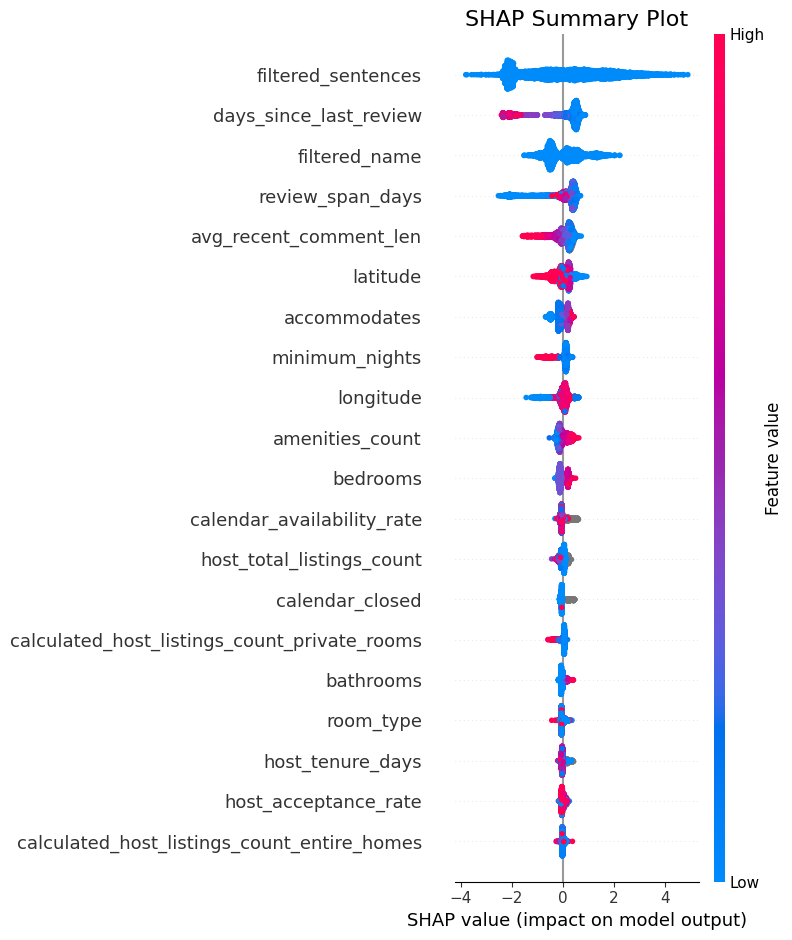

In [34]:
# Summary Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_plot, max_display=20, show=False)
plt.title("SHAP Summary Plot", fontsize=16)
plt.tight_layout()
plt.show()



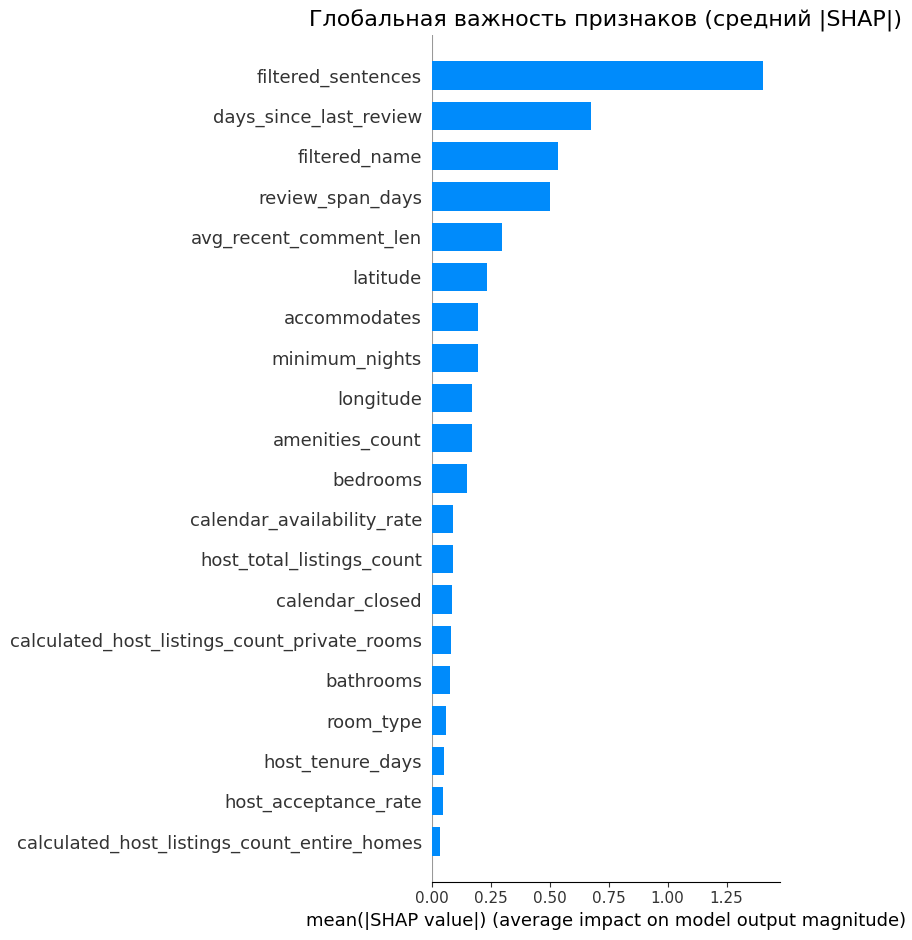

In [35]:
# Bar Plot
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_plot, plot_type="bar", max_display=20, show=False)
plt.title("Глобальная важность признаков (средний |SHAP|)", fontsize=16)
plt.tight_layout()
plt.show()



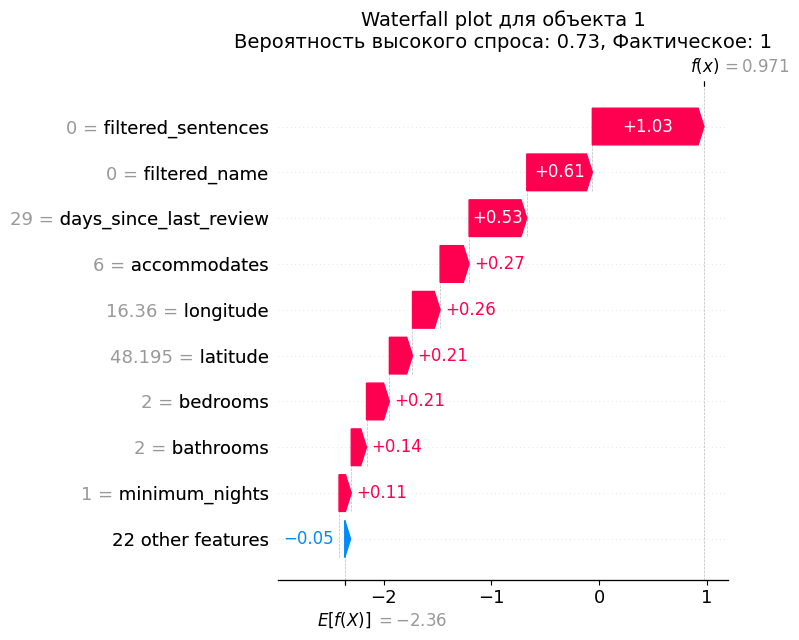

In [36]:
# Waterfall Plot (листинг с высоким спросом)
i = np.where(y_shap.values == 1)[0][0]   # первый объект с реальным высоким спросом

plt.figure(figsize=(12, 6))
shap.plots.waterfall(shap.Explanation(values=shap_values[i],
                                      base_values=expected_value,
                                      data=X_plot.iloc[i].values,
                                      feature_names=X_plot.columns.tolist()),
                     max_display=10, show=False)
plt.title(f"Waterfall plot для объекта {i}\n"
          f"Вероятность высокого спроса: {proba_shap[i]:.2f}, Фактическое: {y_shap.iloc[i]}", fontsize=14)
plt.tight_layout()
plt.show()



**Интерпретация SHAP-анализа:**

По результатам SHAP-анализа можно сделать вивод, что самые важные для предсказания для модели признаки:
filtered_sentences, room_type, days_since_last_review,
filtered_name и review_span_days - это в первую очередь признаки, связанные с отзывами и актуальностью объявлений, что подтверждает EDA-гипотезы.

На спрос сильнее всего влияет «живость» объявления (свежие содержательные отзывы), а не характеристики жилья. Поэтому полезны меры по сбору отзывов и обновлению объявлений.

Результаты SHAPE-анализа важны для бизнеса, т.к. дают понять важность обработки отзывов, а также способы увеличения конверсии за счет контроля актуальности объявлений.


## 9. Карточка модели

Оформите карточку финальной версии модели по шаблону ниже.

### Модель v1.0

**Задача:** бинарная классификация — предсказание высокого спроса на объявление.

**Целевая переменная:** `is_high_demand`.

**Алгоритм:** *CatBoost*.

**Гиперпараметры:** 'iterations': 500,
    'random_state': 42,
    'auto_class_weights': 'Balanced',
    'verbose': 0*

**Признаки:** *31 признак. Категориальные (7): room_type, host_response_time, host_is_superhost, host_identity_verified, instant_bookable, host_has_profile_pic, property_type_top. Текстовые (2): filtered_name, filtered_sentences. Числовые (22): параметры жилья (accommodates, bedrooms, beds, bathrooms, minimum_nights, maximum_nights), координаты, данные хоста, признаки календаря и отзывов (calendar_availability_rate, calendar_closed, avg_recent_comment_len, days_since_last_review, review_span_days), amenities_count, is_long_stay, guests_per_bedroom, guests_per_bathroom.*

**Метрики на тестовой выборке:**

| Метрика | Значение |
|---------|----------|
| PR-AUC | 0.6934|
| ROC-AUC | 0.9298|
| F1 |0.6392 |
| Precision |0.5987 |
| Recall |0.6856 |

**Топ-5 важных признаков по SHAP:**

filtered_sentences            0.7419

room_type                     0.6939

days_since_last_review        0.6746

filtered_name                 0.5168

review_span_days              0.5031

**Ограничения модели:** *Около 40% срабатываний ложные (при Precision 0.60), около 31% реальных объектов пропускается.
Сильнее всего модель опирается на признаки отзывов (avg_recent_comment_len, review_span_days, days_since_last_review, текст отзывов). Модель обучена на объявлениях с известной ценой и рейтингом (111 118 из 364 084), то есть имеющих историю отзывов; для объявлений без отзывов (cold start) качество не проверялось и, скорее всего, ниже.
Модель обучена на одном срезе данных. Признаки времени считаются от даты инференса, при сдвиге даты распределения меняются.*

**Рекомендация к внедрению:** *возможно внедрение в качестве инструмента приоритизации и ранжирования листингов. После запуска мониторить долю положительных предсказаний, долю пропусков в признаках отзывов и качество по городам.*

## 10. Итоговые выводы и рекомендации бизнесу

Напишите краткое резюме для бизнеса: что вы обучили, какого результата достигли, что рекомендуете.

**Выводы:**
Обучена модель CatBoost (500 итераций, auto_class_weights='Balanced', 31 признак без города и расстояния до центра), предсказывающая высокий спрос на объявление (редкий класс, ≈13%). Обучение и тест выполнены на 111 118 объявлениях с известными ценой, рейтингом и числом отзывов. По кросс-валидации она лучше LightGBM и Random Forest (PR-AUC 0.666 против 0.644 и 0.580). Подбор гиперпараметров через Optuna (8 trials на подвыборке) улучшения не дал, оставлена базовая конфигурация. Порог 0.684 подобран по F1 на OOF-предсказаниях.

На тесте PR-AUC 0.693, ROC-AUC 0.930, F1 0.639 (Precision 0.599, Recall 0.686), что не хуже, чем по кросс-валидации, переобучения нет. Модель стабильна и сильно лучше случайной.

Ключевые факторы спроса по SHAP: свежесть и содержательность отзывов, тип жилья (room_type) и название объявления.

Рекомендация: использовать модель как инструмент ранжирования листингов для приоритизации работы с объявлениями, с мониторингом доли пропусков в признаках отзывов.